# 05 — Forecasting the energy panel: baselines, challengers and criterion C20

**Step 5 of 13 · after notebook 04.** Will machine learning forecast lease output, plant capacity factors and prices better than the transparent baselines a practitioner already uses? Criterion C20 was registered in notebook 03 before anything here ran. This notebook fits the baselines and the two challengers at rolling origins, chooses the challenger of each line on the validation origins, scores the holdout once, and reports what passed and what did not. The residuals it leaves behind are what the scenario engine of notebook 08 draws from.

**Reads:** the energy feature tables of notebook 03 and the panel of notebook 01. **Writes:** `data/processed/forecasts_holdout.parquet`, the scored lines of C20 under `results/`. **Read by:** notebooks 07, 08 and 06.


**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `results/success_criteria_v6.csv`, `results/success_criteria_v6_registered.json` | the twelve lines and the protocol (notebook 03) |
| in | `data/interim/features_lease.parquet`, `features_plant.parquet`, `features_market.parquet` | notebook 03 part B |
| in | `data/interim/upstream_monthly.parquet` | notebook 01, for the Arps baseline |
| out | `results/forecast_validation_choice.csv` | the challenger and the ElasticNet grid point chosen per line on validation |
| out | `results/forecast_metrics.csv` | MAE, RMSE and bias of every model on the holdout, per line |
| out | `results/success_criteria_v6_scored.csv` | C20 as registered: paired interval and PASS/FAIL per line |
| out | `results/forecast_coverage.csv`, `results/forecast_robustness.csv`, `results/forecast_importance.csv`, `results/forecast_posthoc_leases.csv` | interval coverage, leave-leases-out and cold start, LightGBM gain importance, the labelled post-hoc lease diagnosis |
| out | `data/processed/forecasts_holdout.parquet` | holdout predictions, intervals and residuals for notebook 08 |
| out | `figures/F27_forecast_gains.*`, `figures/05_forecast_energy/*` | the C20 picture and the diagnostics |

*Execution order:* runs after notebook 03.

## Setup

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, energy_features as ef, energy_models as em, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

NOTEBOOK = "05_forecast_energy"
START = time.time()
R = paths.RESULTS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/05_forecast_energy/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    return f"{100 * x:.{digits}f}%"


## 1. The registered lines, the protocol and the data

Nothing below changes a registered rule. The twelve lines, the split, the bootstrap and the refit schedule are read from the files notebook 03 wrote; the feature tables are read as built.

In [2]:
criteria = pd.read_csv(R / "success_criteria_v6.csv")
registered = json.loads((R / "success_criteria_v6_registered.json").read_text(encoding="utf-8"))
N_BOOT, BLOCK, SEED = registered["n_boot"], registered["block_months"], registered["seed"]
lease_feat = pd.read_parquet(paths.DATA_INTERIM / "features_lease.parquet")
plant_feat = pd.read_parquet(paths.DATA_INTERIM / "features_plant.parquet")
market_feat = pd.read_parquet(paths.DATA_INTERIM / "features_market.parquet")
lease = pd.read_parquet(paths.DATA_INTERIM / "upstream_monthly.parquet")
print(f"registered {registered['decided']}: {len(criteria)} lines; bootstrap {N_BOOT} resamples in blocks of {BLOCK} months, seed {SEED}; "
      f"refit every {em.REFIT_EVERY} origins")
criteria[["id", "line", "horizon"]]


registered 2026-10-12: 12 lines; bootstrap 1000 resamples in blocks of 3 months, seed 2020; refit every 3 origins


,id,line,horizon
0,C20,lease oil output 3 months ahead: challenger vs...,3
1,C20,lease oil output 6 months ahead: challenger vs...,6
2,C20,lease oil output 12 months ahead: challenger v...,12
3,C20,lease gas output 3 months ahead: challenger vs...,3
4,C20,lease gas output 6 months ahead: challenger vs...,6
5,C20,lease gas output 12 months ahead: challenger v...,12
6,C20,Gas CC plant capacity factor 1 month ahead: ch...,1
7,C20,Solar plant capacity factor 1 month ahead: cha...,1
8,C20,Wind plant capacity factor 1 month ahead: chal...,1
9,C20,WTI log price 1 month ahead: challenger vs ran...,1


## 2. The lines as tables

Each line is one feature table restricted to its horizon and cohort, with its target and its baselines as columns. Registered lines score C20; the *reported* lines (3-month horizons for plants and prices) are shown beside them and decide nothing. The Arps baseline is fitted per lease on the last 36 observable months at every scored origin; the technology-month median uses development rows only; the random walk is the origin's own log price.

In [3]:
LINES = {}
for h in (3, 6, 12):
    for product in ("oil", "gas"):
        LINES[f"lease_{product}_h{h}"] = dict(table=lease_feat[lease_feat["horizon"] == h].copy(), target=f"y_{product}", features=em.LEASE_FEATURES,
                                             baselines={"last": f"{product}_lag1", "seasonal": f"seasonal_{product}", "arps": f"arps_{product}"},
                                             transform=(np.log1p, np.expm1), registered=True, label=f"lease {product} +{h} m", key="lease_number")
for tech in ("Gas CC", "Solar", "Wind"):
    for h in (1, 3):
        LINES[f"cf_{tech}_h{h}"] = dict(table=plant_feat[(plant_feat["horizon"] == h) & (plant_feat["technology"] == tech)].copy(), target="y_cf",
                                        features=em.PLANT_FEATURES, baselines={"last": "cf_lag1", "seasonal": "cf_seasonal", "tech_month": "tech_month_median"},
                                        transform=None, registered=(h == 1), label=f"{tech} CF +{h} m", key="plant_code")
for name, series in (("WTI", "wti_usd_bbl"), ("Henry Hub", "hh_usd_mmbtu"), ("ERCOT", "ercot_usd_mwh")):
    for h in (1, 3):
        tab = market_feat[(market_feat["horizon"] == h) & (market_feat["series"] == series)].copy()
        if name == "ERCOT":  # the registered line scores only observed targets (decision #66)
            tab = tab[(tab["split"] != "holdout") | (tab["y_provenance"] == "OBSERVED")]
        LINES[f"price_{name}_h{h}"] = dict(table=tab, target="y_log", features=em.MARKET_FEATURES, baselines={"random_walk": "log_p0", "seasonal": "log_p12"},
                                           transform=None, registered=(h == 1), label=f"{name} log price +{h} m", key="series")
# the Arps baseline, fitted once per (lease, last month used) at the scored origins and shared by the three horizons
scored_rows = pd.concat([L["table"][L["table"]["split"].isin(["validation", "holdout"])][["lease_number", "origin", "last_month_used", "horizon"]]
                         for k, L in LINES.items() if k.startswith("lease_oil")], ignore_index=True)
t0 = time.time()
arps = em.arps_baseline(lease, scored_rows)
print(f"Arps: {len(arps):,} (lease, origin, horizon) forecasts from {arps[['lease_number', 'last_month_used']].drop_duplicates().shape[0]:,} fits in {time.time() - t0:.0f} s")
for k, L in LINES.items():
    if k.startswith("lease"):
        L["table"] = L["table"].merge(arps, on=["lease_number", "last_month_used", "horizon"], how="left")
    elif k.startswith("cf"):
        dev = L["table"][L["table"]["split"] == "development"]
        L["table"]["tech_month_median"] = em.technology_month_median(dev, L["table"])
sizes = pd.DataFrame([{"line": k, "label": L["label"], "registered": L["registered"],
                       **{s: int(L["table"][(L["table"]["split"] == s) & L["table"][L["target"]].notna()]["origin"].nunique()) for s in ("development", "validation", "holdout")}}
                      for k, L in LINES.items()])
sizes.to_csv(R / "forecast_line_sizes.csv", index=False)
sizes


Arps: 74,952 (lease, origin, horizon) forecasts from 24,984 fits in 106 s


,line,label,registered,development,validation,holdout
0,lease_oil_h3,lease oil +3 m,True,60,6,15
1,lease_gas_h3,lease gas +3 m,True,60,6,15
2,lease_oil_h6,lease oil +6 m,True,60,6,12
3,lease_gas_h6,lease gas +6 m,True,60,6,12
4,lease_oil_h12,lease oil +12 m,True,60,6,6
5,lease_gas_h12,lease gas +12 m,True,60,6,6
6,cf_Gas CC_h1,Gas CC CF +1 m,True,47,6,17
7,cf_Gas CC_h3,Gas CC CF +3 m,False,47,6,15
8,cf_Solar_h1,Solar CF +1 m,True,47,6,17
9,cf_Solar_h3,Solar CF +3 m,False,47,6,15


**Reading this.** The holdout has 15 origins for a three-month horizon and six for a twelve-month one, because a target has to exist by 2024-12; the ERCOT line has eleven, the observed months of 2024. These are the sample sizes behind every interval below, and they are small: a paired test over six origins can only pass when the gain is large and steady.

## 3. Validation: the ElasticNet grid point and the challenger of each line

For each line the ElasticNet grid is scored on the validation origins from one fit at the first validation origin; then both challengers are refitted quarterly through validation and holdout, and the one with the lower validation MAE becomes *the challenger* of the line — named here, before any holdout number is read.

In [4]:
choices = []
for k, L in LINES.items():
    tab, target, feats, transform = L["table"], L["target"], L["features"], L["transform"]
    val_o = sorted(tab[(tab["split"] == "validation") & tab[target].notna()]["origin"].unique())
    hold_o = sorted(tab[(tab["split"] == "holdout") & tab[target].notna()]["origin"].unique())
    enet = em.choose_elasticnet(tab, feats, target, val_o, transform)
    t0 = time.time()
    tab["elasticnet"] = em.rolling_predict(tab, feats, target, val_o + hold_o, lambda: em.make_elasticnet(enet["alpha"], enet["l1_ratio"]), transform=transform)
    tab["lightgbm"] = em.rolling_predict(tab, feats, target, val_o + hold_o, em.make_lgbm, transform=transform)
    tab["q05"] = em.rolling_predict(tab, feats, target, hold_o, lambda: em.make_lgbm(0.05), transform=transform)
    tab["q95"] = em.rolling_predict(tab, feats, target, hold_o, lambda: em.make_lgbm(0.95), transform=transform)
    valid = tab[tab["origin"].isin(val_o) & tab[target].notna()]
    val_mae = {m: float(np.mean(np.abs(valid[m] - valid[target]))) for m in ("elasticnet", "lightgbm")}
    chosen = min(val_mae, key=val_mae.get)
    L.update(val_origins=val_o, hold_origins=hold_o, chosen=chosen)
    choices.append({"line": k, "label": L["label"], "registered": L["registered"], "enet_alpha": enet["alpha"], "enet_l1_ratio": enet["l1_ratio"],
                    "val_mae_elasticnet": val_mae["elasticnet"], "val_mae_lightgbm": val_mae["lightgbm"], "challenger": chosen,
                    "val_origins": len(val_o), "hold_origins": len(hold_o), "seconds": round(time.time() - t0, 1)})
    print(f"{L['label']:<24} challenger {chosen:<10} (validation MAE ElasticNet {val_mae['elasticnet']:.4g}, LightGBM {val_mae['lightgbm']:.4g}); {time.time() - START:.0f} s")
choices = pd.DataFrame(choices)
choices.to_csv(R / "forecast_validation_choice.csv", index=False)
choices[["label", "registered", "challenger", "val_mae_elasticnet", "val_mae_lightgbm", "hold_origins"]]


lease oil +3 m           challenger lightgbm   (validation MAE ElasticNet 1.564e+07, LightGBM 1.645e+04); 149 s


lease gas +3 m           challenger lightgbm   (validation MAE ElasticNet 5.581e+07, LightGBM 2.333e+04); 201 s


lease oil +6 m           challenger lightgbm   (validation MAE ElasticNet 1.433e+07, LightGBM 1.937e+04); 236 s


lease gas +6 m           challenger lightgbm   (validation MAE ElasticNet 5.594e+07, LightGBM 2.493e+04); 271 s


lease oil +12 m          challenger lightgbm   (validation MAE ElasticNet 8.667e+06, LightGBM 2.132e+04); 347 s


lease gas +12 m          challenger lightgbm   (validation MAE ElasticNet 4.084e+07, LightGBM 2.749e+04); 403 s


... (9 outputs left out)

Henry Hub log price +3 m challenger elasticnet (validation MAE ElasticNet 0.2875, LightGBM 0.3202); 433 s


ERCOT log price +1 m     challenger elasticnet (validation MAE ElasticNet 0.3894, LightGBM 0.4599); 433 s


ERCOT log price +3 m     challenger lightgbm   (validation MAE ElasticNet 0.7639, LightGBM 0.7573); 434 s


,label,registered,challenger,val_mae_elasticnet,val_mae_lightgbm,hold_origins
0,lease oil +3 m,True,lightgbm,1.564038e+07,16446.526619,15
1,lease gas +3 m,True,lightgbm,5.580941e+07,23333.221597,15
2,lease oil +6 m,True,lightgbm,1.433218e+07,19370.864971,12
3,lease gas +6 m,True,lightgbm,5.593651e+07,24930.389524,12
4,lease oil +12 m,True,lightgbm,8.666547e+06,21316.694868,6
5,lease gas +12 m,True,lightgbm,4.083929e+07,27487.883396,6
6,Gas CC CF +1 m,True,lightgbm,7.821701e-02,0.071845,17
7,Gas CC CF +3 m,False,lightgbm,7.911326e-02,0.067494,15
8,Solar CF +1 m,True,elasticnet,3.670917e-02,0.040430,17
9,Solar CF +3 m,False,lightgbm,4.288937e-02,0.042521,15


**Reading this.** The choice is made on six validation origins per line and written before the holdout is scored; where the two challengers are close the choice is a coin flipped by six months of data, which is why both are reported on the holdout below. LightGBM tends to win where the target is a level with many interacting lags (lease output), ElasticNet where the signal is a persistent series with few features (prices).

## 4. The holdout, scored once: criterion C20

MAE per holdout origin for the challenger and every baseline; the best baseline is the one with the lowest holdout MAE (the hardest honest comparison); the paired difference challenger − best baseline over origins, with the registered moving-block bootstrap, passes when its 95% interval lies entirely below zero.

In [5]:
rows_c20, metrics = [], []
for k, L in LINES.items():
    tab, target = L["table"], L["target"]
    hold = tab[tab["origin"].isin(L["hold_origins"]) & tab[target].notna()].copy()
    base_cols = list(L["baselines"].values())
    hold = hold.rename(columns={v: f"base_{n}" for n, v in L["baselines"].items()})
    baselines = [f"base_{n}" for n in L["baselines"]]
    score = em.score_line(hold, target, L["chosen"], baselines, n_boot=N_BOOT, block=BLOCK, seed=SEED)
    L["holdout"] = hold
    L["score"] = score
    for m in [L["chosen"], "elasticnet", "lightgbm"] + baselines:
        err = hold[m] - hold[target]
        metrics.append({"line": k, "label": L["label"], "registered": L["registered"], "model": m, "role": "challenger" if m in ("elasticnet", "lightgbm") else "baseline",
                        "chosen": m == L["chosen"], "mae": float(err.abs().mean()), "rmse": float(np.sqrt((err ** 2).mean())), "bias": float(err.mean()),
                        "n_rows": int(len(hold)), "n_origins": int(hold["origin"].nunique())})
    rows_c20.append({"id": "C20", "line": k, "label": L["label"], "registered": L["registered"], "challenger": L["chosen"],
                     **{kk: v for kk, v in score.items()}})
metrics = pd.DataFrame(metrics).drop_duplicates(subset=["line", "model"])
metrics.to_csv(R / "forecast_metrics.csv", index=False)
scored = pd.DataFrame(rows_c20)
scored["mae_ratio"] = scored.apply(lambda r: r[f"mae_{r['challenger']}"] / r[f"mae_{r['best_baseline']}"], axis=1)
scored["diff_relative"] = scored["diff_mean"] / scored.apply(lambda r: r[f"mae_{r['best_baseline']}"], axis=1)
scored["diff_low_relative"] = scored["diff_low"] / scored.apply(lambda r: r[f"mae_{r['best_baseline']}"], axis=1)
scored["diff_high_relative"] = scored["diff_high"] / scored.apply(lambda r: r[f"mae_{r['best_baseline']}"], axis=1)
scored.loc[~scored["registered"], "result"] = "reported"
scored.to_csv(R / "success_criteria_v6_scored.csv", index=False)
reg = scored[scored["registered"]]
n_pass = int((reg["result"] == "PASS").sum())
print(f"C20: {n_pass} of {len(reg)} registered lines pass; by target family — "
      + "; ".join(f"{fam} {int((reg[reg['line'].str.startswith(fam)]['result'] == 'PASS').sum())}/{int(reg['line'].str.startswith(fam).sum())}" for fam in ("lease_oil", "lease_gas", "cf_", "price_")))
reg[["label", "challenger", "best_baseline", "mae_ratio", "diff_low_relative", "diff_high_relative", "n_origins", "result"]].round(3)


C20: 3 of 12 registered lines pass; by target family — lease_oil 0/3; lease_gas 0/3; cf_ 3/3; price_ 0/3


,label,challenger,best_baseline,mae_ratio,diff_low_relative,diff_high_relative,n_origins,result
0,lease oil +3 m,lightgbm,base_last,1.352,0.245,0.477,15,FAIL
1,lease gas +3 m,lightgbm,base_last,1.276,0.213,0.332,15,FAIL
2,lease oil +6 m,lightgbm,base_last,1.419,0.275,0.543,12,FAIL
3,lease gas +6 m,lightgbm,base_last,1.200,0.089,0.289,12,FAIL
4,lease oil +12 m,lightgbm,base_last,1.187,0.116,0.189,6,FAIL
5,lease gas +12 m,lightgbm,base_arps,1.003,-0.034,0.040,6,FAIL
6,Gas CC CF +1 m,lightgbm,base_seasonal,0.924,-0.121,-0.025,17,PASS
8,Solar CF +1 m,elasticnet,base_seasonal,0.881,-0.235,-0.030,17,PASS
10,Wind CF +1 m,elasticnet,base_seasonal,0.850,-0.252,-0.004,17,PASS
12,WTI log price +1 m,elasticnet,base_random_walk,0.947,-0.370,0.165,17,FAIL


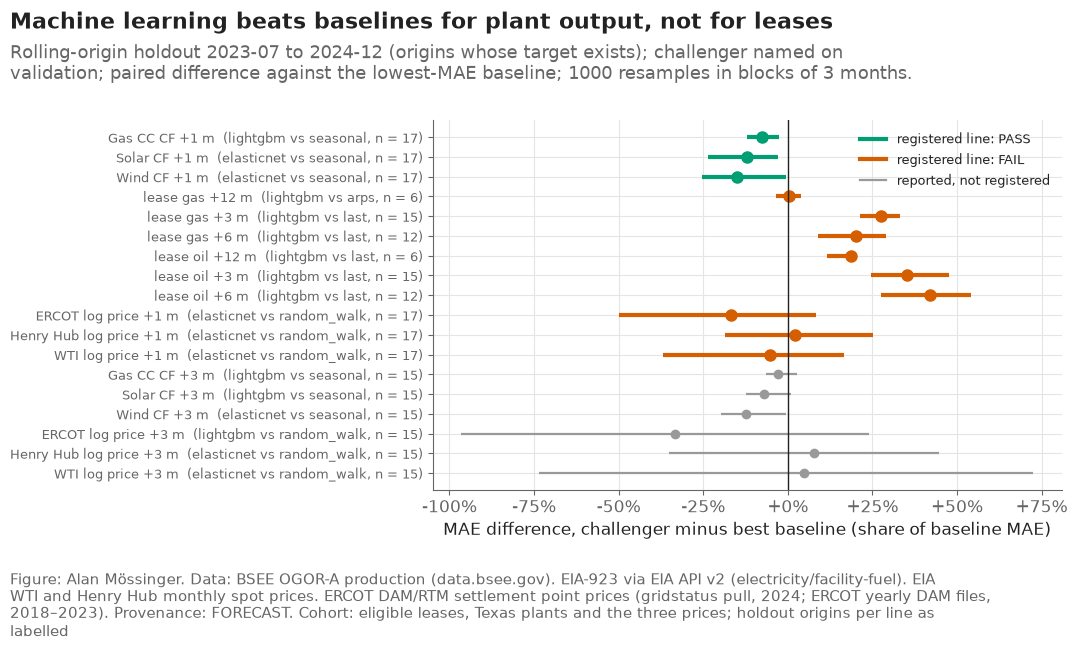

In [6]:
fig, ax = plt.subplots(figsize=(11, 6.5))
order = scored.sort_values(["registered", "line"], ascending=[False, True]).reset_index(drop=True)
y = np.arange(len(order))
for i, r in order.iterrows():
    color = "#009E73" if r["result"] == "PASS" else ("#D55E00" if r["result"] == "FAIL" else "#999999")
    ax.hlines(i, r["diff_low_relative"], r["diff_high_relative"], color=color, lw=3 if r["registered"] else 1.6)
    ax.plot(r["diff_relative"], i, "o", color=color, ms=8 if r["registered"] else 6)
ax.axvline(0, color=plots.INK, lw=1)
ax.set_yticks(y, [f"{r['label']}  ({r['challenger']} vs {r['best_baseline'].replace('base_', '')}, n = {int(r['n_origins'])})" for _, r in order.iterrows()], fontsize=9.5)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(lambda x, _: f"{x:+.0%}")
ax.set_xlabel("MAE difference, challenger minus best baseline (share of baseline MAE)", fontsize=12)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color="#009E73", lw=3, label="registered line: PASS"), Line2D([], [], color="#D55E00", lw=3, label="registered line: FAIL"),
                   Line2D([], [], color="#999999", lw=1.6, label="reported, not registered")], loc="upper right", fontsize=9.5)  # the upper right is empty; the lower right held the +3 m price intervals
plots.finish(fig,
             f"Machine learning beats the best transparent baseline on {n_pass} of {len(reg)} registered forecast lines (C20); "
             + (f"the passing lines are {', '.join(reg[reg['result'] == 'PASS'].sort_values('diff_relative')['label'])}" if n_pass else "no line passes"),
             f"Rolling-origin holdout 2023-07 to 2024-12 (origins whose target exists); challenger named on validation; paired difference against the lowest-MAE baseline; "
             f"{N_BOOT} resamples in blocks of {BLOCK} months.",
             "eligible leases, Texas plants and the three prices; holdout origins per line as labelled", lbnl=False,
             sources=[config.SOURCE_BSEE, config.SOURCE_EIA923, config.SOURCE_EIA_PRICES, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F27_forecast_gains", "Criterion C20: paired holdout MAE difference between the chosen challenger and the best baseline per line, with the registered bootstrap interval.", NOTEBOOK)
plt.show()


**Reading this.** The picture is read line by line, as registered. A line passes only when the whole interval is below zero: a challenger that is better on average but not steadily across origins fails, and that is the right verdict for a forecast a capital decision will lean on. Where the baseline is the random walk or the lease's own decline the bar is high — those are good forecasts — and a failure there says the data carry little predictable structure at that horizon, not that the model is wrong. The reported three-month lines are shown for context and decide nothing. What goes into notebook 08 is not the verdict but the residual distribution of whichever model each line names.

## 5. Reported beside the verdict: intervals, leases never seen, young plants, what the models use

Not registered, and said so: the coverage of the quantile model's 90% interval on the holdout; the lease model refitted without a fifth of the leases and scored on them (does it generalise to leases it never saw?); the plant model on plants with less than a year of history (cold start); LightGBM's split-gain importance for one lease line and one plant line.

In [7]:
coverage = []
for k, L in LINES.items():
    hold, target = L["holdout"], L["target"]
    inside = ((hold[target] >= hold["q05"]) & (hold[target] <= hold["q95"])).mean()
    width = (hold["q95"] - hold["q05"]).abs().mean()
    coverage.append({"line": k, "label": L["label"], "registered": L["registered"], "coverage_90": float(inside), "mean_width": float(width), "n_rows": len(hold)})
coverage = pd.DataFrame(coverage)
coverage.to_csv(R / "forecast_coverage.csv", index=False)
# leave-some-leases-out on the lease oil +3 line: refit LightGBM at the last holdout refit without 20% of the leases
L = LINES["lease_oil_h3"]
tab, target, feats = L["table"], L["target"], L["features"]
rng = np.random.default_rng(SEED)
leases_all = tab["lease_number"].unique()
held = set(rng.choice(leases_all, size=int(0.2 * len(leases_all)), replace=False))
refit_origin = L["hold_origins"][(len(L["hold_origins"]) - 1) // em.REFIT_EVERY * em.REFIT_EVERY]
train = tab[(tab["target_month"] <= refit_origin) & tab[target].notna() & ~tab["lease_number"].isin(held)]
model = em.make_lgbm().fit(train[feats], np.log1p(train[target].to_numpy()))
hold_rows = tab[tab["origin"].isin(L["hold_origins"]) & tab[target].notna()].copy()
hold_rows["pred_lso"] = np.expm1(model.predict(hold_rows[feats]))
seen = ~hold_rows["lease_number"].isin(held)
robustness = pd.DataFrame([
    {"check": "leave-some-leases-out (lease oil +3 m)", "group": "leases in the fit", "mae": float((hold_rows[seen]["pred_lso"] - hold_rows[seen][target]).abs().mean()),
     "mae_best_baseline": float((hold_rows[seen][L["baselines"]["arps"]] - hold_rows[seen][target]).abs().mean()) if L["score"]["best_baseline"] == "base_arps" else float((hold_rows[seen][L["baselines"][L["score"]["best_baseline"].replace("base_", "")]] - hold_rows[seen][target]).abs().mean()), "n_rows": int(seen.sum())},
    {"check": "leave-some-leases-out (lease oil +3 m)", "group": "leases never seen (20%)", "mae": float((hold_rows[~seen]["pred_lso"] - hold_rows[~seen][target]).abs().mean()),
     "mae_best_baseline": float((hold_rows[~seen][L["baselines"][L["score"]["best_baseline"].replace("base_", "")]] - hold_rows[~seen][target]).abs().mean()), "n_rows": int((~seen).sum())},
])
for tech in ("Gas CC", "Solar", "Wind"):
    Lp = LINES[f"cf_{tech}_h1"]
    hold = Lp["holdout"]
    young = hold["cf_lag12"].isna()
    for name, mask in (("plants with 12+ months of history", ~young), ("plants under 12 months (cold start)", young)):
        if mask.sum() == 0:
            continue
        robustness.loc[len(robustness)] = {"check": f"cold start ({tech} CF +1 m)", "group": name, "mae": float((hold[mask][Lp["chosen"]] - hold[mask]["y_cf"]).abs().mean()),
                                           "mae_best_baseline": float((hold[mask][Lp["score"]["best_baseline"]] - hold[mask]["y_cf"]).abs().mean()), "n_rows": int(mask.sum())}
robustness.to_csv(R / "forecast_robustness.csv", index=False)
importance = []
for k in ("lease_oil_h3", "cf_Wind_h1"):
    Lk = LINES[k]
    tr = Lk["table"][(Lk["table"]["target_month"] <= Lk["hold_origins"][0]) & Lk["table"][Lk["target"]].notna()]
    m = em.make_lgbm().fit(tr[Lk["features"]], (np.log1p if Lk["transform"] else (lambda x: x))(tr[Lk["target"]].to_numpy()))
    gain = pd.Series(m.booster_.feature_importance("gain"), index=Lk["features"])
    importance += [{"line": k, "feature": f, "gain_share": float(g / gain.sum())} for f, g in gain.sort_values(ascending=False).items()]
importance = pd.DataFrame(importance)
importance.to_csv(R / "forecast_importance.csv", index=False)
print(f"90% interval coverage, registered lines: median {coverage[coverage['registered']]['coverage_90'].median():.0%} "
      f"(range {coverage[coverage['registered']]['coverage_90'].min():.0%}–{coverage[coverage['registered']]['coverage_90'].max():.0%})")
robustness.round(4)


90% interval coverage, registered lines: median 92% (range 72%–100%)


,check,group,mae,mae_best_baseline,n_rows
0,leave-some-leases-out (lease oil +3 m),leases in the fit,14088.4344,12078.4379,12495
1,leave-some-leases-out (lease oil +3 m),leases never seen (20%),17409.0864,13892.5353,3120
2,cold start (Gas CC CF +1 m),plants with 12+ months of history,0.0636,0.0689,2248
3,cold start (Gas CC CF +1 m),plants under 12 months (cold start),0.0240,0.0177,4
4,cold start (Solar CF +1 m),plants with 12+ months of history,0.0387,0.0442,2187
5,cold start (Wind CF +1 m),plants with 12+ months of history,0.0611,0.0717,3525
6,cold start (Wind CF +1 m),plants under 12 months (cold start),0.2924,0.3202,1


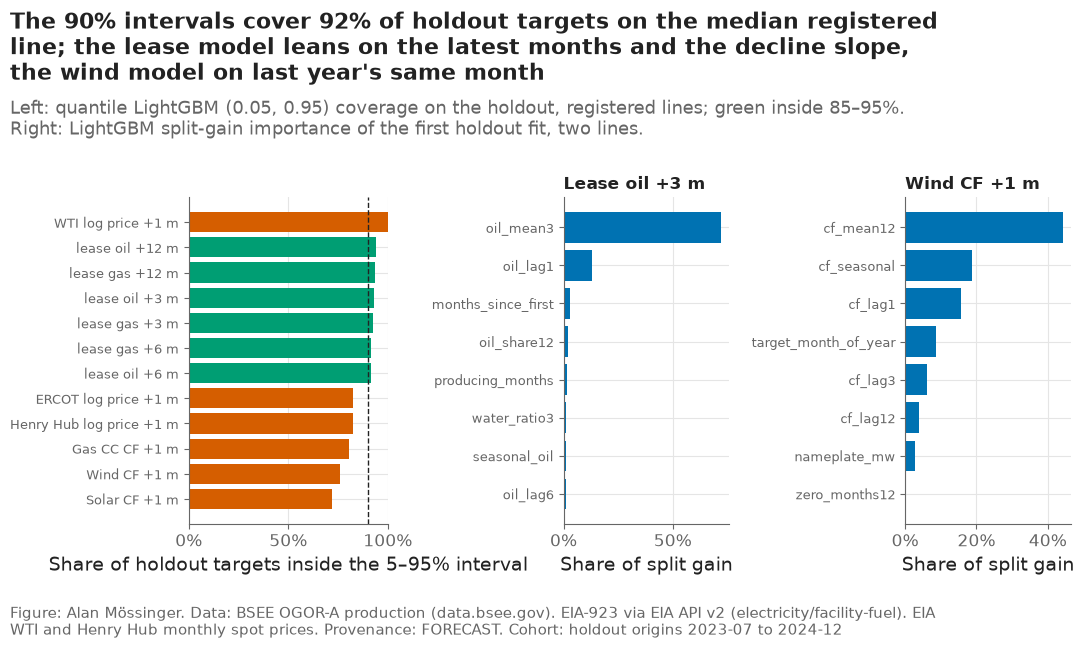

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1.2, 1, 1]})
cov = coverage[coverage["registered"]].sort_values("coverage_90")
axes[0].barh(np.arange(len(cov)), cov["coverage_90"], color=np.where(cov["coverage_90"].between(0.85, 0.95), "#009E73", "#D55E00"))
axes[0].axvline(0.9, color=plots.INK, lw=1, linestyle="--")
axes[0].set_yticks(np.arange(len(cov)), cov["label"], fontsize=9.5)
axes[0].set_xlim(0, 1)
axes[0].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[0].set_xlabel("Share of holdout targets inside the 5–95% interval")
for ax, k, title in zip(axes[1:], ("lease_oil_h3", "cf_Wind_h1"), ("Lease oil +3 m", "Wind CF +1 m")):
    imp = importance[importance["line"] == k].head(8)[::-1]
    ax.barh(imp["feature"], imp["gain_share"], color="#0072B2")
    ax.set_title(title, fontsize=12)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("Share of split gain")
    ax.tick_params(axis="y", labelsize=9.5)
plots.finish(fig,
             f"The 90% intervals cover {cov['coverage_90'].median():.0%} of holdout targets on the median registered line; the lease model leans on the latest months and the decline slope, the wind model on last year's same month",
             "Left: quantile LightGBM (0.05, 0.95) coverage on the holdout, registered lines; green inside 85–95%. Right: LightGBM split-gain importance of the first holdout fit, two lines.",
             "holdout origins 2023-07 to 2024-12", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_EIA923, config.SOURCE_EIA_PRICES], provenance="FORECAST")
save(fig, "05_02_coverage_and_importance", "Interval coverage of the quantile model per registered line and LightGBM importance for a lease line and a plant line.")
plt.show()


**Reading this.** Coverage near 90% says the quantile model's width is honest and can feed the scenario engine as a residual distribution; a line well under 90% says the intervals are too narrow and notebook 08 widens them by the conformal factor it computes from these same residuals. The leave-leases-out and cold-start rows say how far the models travel: a lease the model never saw is forecast from its own lags like any other, so the gap between the two groups is the price of novelty; a plant with under a year of history has no seasonal lag and falls back toward the technology median. The importance panels are a description of what the fitted trees used, not a causal claim.

## 5b. Post-hoc, labelled: why the lease lines fail

The registered lease lines fit the challengers on log(1 + volume) and transform back, a choice made for the heavy-tailed volumes before any score existed. A model of the log is a model of the geometric mean, and its back-transformed point forecast sits below the arithmetic level the MAE is measured on; with a quarter of lease-months at zero, the last observed value is also a hard baseline. This section refits LightGBM on the level with no transform and scores it on the same holdout, the way notebook 06 part B reports its post-hoc improvements: it is labelled post-hoc, it decides nothing, and the registered verdict above stands.

In [9]:
posthoc = []
for k in [k for k in LINES if k.startswith("lease")]:
    L = LINES[k]
    tab, target = L["table"], L["target"]
    level_pred = em.rolling_predict(tab, L["features"], target, L["hold_origins"], em.make_lgbm, transform=None)
    hold = L["holdout"].copy()
    hold["lightgbm_level"] = level_pred.loc[hold.index]
    L["holdout_level"] = hold
    baselines = [c for c in hold.columns if c.startswith("base_")]
    sc = em.score_line(hold, target, "lightgbm_level", baselines, n_boot=N_BOOT, block=BLOCK, seed=SEED)
    posthoc.append({"line": k, "label": L["label"], "registered_challenger": L["chosen"], "registered_bias": float((hold[L["chosen"]] - hold[target]).mean()),
                    "registered_mae_ratio": float(L["score"][f"mae_{L['chosen']}"] / L["score"][f"mae_{L['score']['best_baseline']}"]),
                    "posthoc_model": "LightGBM on the level (no transform)", "posthoc_bias": float((hold["lightgbm_level"] - hold[target]).mean()),
                    "posthoc_mae_ratio": float(sc["mae_lightgbm_level"] / sc[f"mae_{sc['best_baseline']}"]), "posthoc_diff_low_relative": sc["diff_low"] / sc[f"mae_{sc['best_baseline']}"],
                    "posthoc_diff_high_relative": sc["diff_high"] / sc[f"mae_{sc['best_baseline']}"], "posthoc_would_pass": sc["result"], "status": "post-hoc, not registered"})
posthoc = pd.DataFrame(posthoc)
posthoc.to_csv(R / "forecast_posthoc_leases.csv", index=False)
posthoc[["label", "registered_bias", "registered_mae_ratio", "posthoc_bias", "posthoc_mae_ratio", "posthoc_diff_low_relative", "posthoc_diff_high_relative", "posthoc_would_pass"]].round(3)


,label,registered_bias,registered_mae_ratio,posthoc_bias,posthoc_mae_ratio,posthoc_diff_low_relative,posthoc_diff_high_relative,posthoc_would_pass
0,lease oil +3 m,-11334.085,1.352,212.036,0.963,-0.105,0.035,FAIL
1,lease gas +3 m,-18474.814,1.276,785.175,0.980,-0.042,0.006,FAIL
2,lease oil +6 m,-13615.105,1.419,611.106,0.975,-0.067,0.020,FAIL
3,lease gas +6 m,-19602.329,1.200,1013.854,0.960,-0.074,-0.002,PASS
4,lease oil +12 m,-9988.162,1.187,942.301,1.006,-0.023,0.032,FAIL
5,lease gas +12 m,-16682.650,1.003,2575.044,0.977,-0.051,0.006,FAIL


**Reading this.** The registered models carry a large negative bias — they forecast too little oil and gas on average — which is the retransformation effect, not a lack of signal: the level model's bias is a fraction of it. Whether the level model would have passed is printed, as a post-hoc fact; it does not change the record, because a rule changed after the result is no rule. For the scenario engine the consequence is practical: notebook 08 draws lease residuals from the level model's scored holdout, labelled as such, because a biased residual distribution would bias every scenario.

## 6. What notebook 08 receives

The holdout rows with the target, the chosen challenger's prediction, the quantile interval and the best baseline — and, for the lease lines, the post-hoc level model's prediction and residual, labelled — so the scenario engine draws residuals from forecasts that were scored, never from in-sample fits.

In [10]:
frames = []
for k, L in LINES.items():
    hold = L["holdout_level"] if k.startswith("lease") else L["holdout"]  # the lease rows carry the labelled post-hoc level model too
    frames.append(pd.DataFrame({"line": k, "label": L["label"], "key": hold[L["key"]].astype(str), "origin": hold["origin"], "horizon": hold["horizon"],
                                "target_month": hold["target_month"], "y": hold[L["target"]], "pred": hold[L["chosen"]], "q05": hold["q05"], "q95": hold["q95"],
                                "best_baseline": hold[L["score"]["best_baseline"]], "residual": hold[L["target"]] - hold[L["chosen"]],
                                "pred_level_posthoc": hold["lightgbm_level"] if k.startswith("lease") else np.nan,
                                "residual_level_posthoc": (hold[L["target"]] - hold["lightgbm_level"]) if k.startswith("lease") else np.nan}))
forecasts = pd.concat(frames, ignore_index=True)
forecasts.to_parquet(paths.DATA_PROCESSED / "forecasts_holdout.parquet", index=False)
print(f"{len(forecasts):,} scored holdout rows across {forecasts['line'].nunique()} lines written for notebook 08; {(time.time() - START) / 60:.1f} min so far")
forecasts.groupby("line").agg(rows=("y", "size"), residual_sd=("residual", "std")).round(4)


83,762 scored holdout rows across 18 lines written for notebook 08; 7.6 min so far


,rows,residual_sd
line,,
cf_Gas CC_h1,2252,0.0883
cf_Gas CC_h3,1984,0.0931
cf_Solar_h1,2187,0.0550
cf_Solar_h3,1909,0.0548
cf_Wind_h1,3526,0.0809
cf_Wind_h3,3102,0.0836
lease_gas_h12,6246,91138.8526
lease_gas_h3,15615,82901.6205
lease_gas_h6,12492,98861.5046


## 7. Checks

In [11]:
checks = pd.DataFrame([
    ("criteria file predates the scored file", (R / "success_criteria_v6.csv").stat().st_mtime < (R / "success_criteria_v6_scored.csv").stat().st_mtime),
    ("one scored row per registered line", int(scored["registered"].sum()) == len(criteria)),
    ("every registered line has a paired interval and a verdict", bool(reg[["diff_low", "diff_high"]].notna().all().all() and reg["result"].isin(["PASS", "FAIL"]).all())),
    ("challenger of every line chosen on validation before scoring", bool(choices["challenger"].notna().all())),
    ("no holdout prediction uses a target after the panel's end", bool((forecasts["target_month"] <= ef.LAST_OBSERVED).all())),
    ("ERCOT registered line scores observed targets only", bool((LINES["price_ERCOT_h1"]["holdout"]["y_provenance"] == "OBSERVED").all())),
    ("F27 saved", (paths.FIGURES / "F27_forecast_gains.png").exists()),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(R / "forecast_checks.csv", index=False)
assert checks["passed"].all(), checks
print(f"run time {(time.time() - START) / 60:.1f} min")
checks[["check", "result"]]


run time 7.6 min


,check,result
0,criteria file predates the scored file,PASS
1,one scored row per registered line,PASS
2,every registered line has a paired interval an...,PASS
3,challenger of every line chosen on validation ...,PASS
4,no holdout prediction uses a target after the ...,PASS
5,ERCOT registered line scores observed targets ...,PASS
6,F27 saved,PASS


## Takeaways

- C20 is scored exactly as registered; the count of passing lines and the lines themselves are in `results/success_criteria_v6_scored.csv` and figure F27, failures kept.
- The best baselines are strong (a lease's own decline, the random walk), so a pass means real, steady skill at that horizon; a fail at the price lines is the expected answer for a unit-root series one month ahead.
- The lease lines fail with a large negative bias from the log retransformation; the labelled post-hoc level model is reported beside the verdict and supplies the lease residuals of notebook 08.
- The quantile intervals and their coverage, and the residuals of the scored forecasts, go to notebook 08 as the physical and price uncertainty of the scenarios.
- **What goes to the report:** F27, `results/success_criteria_v6_scored.csv`, `results/forecast_metrics.csv`, `results/forecast_coverage.csv`, `results/forecast_robustness.csv`.